# 02 Optimal mix

Which mix of solar PV, battery and diesel generator supplies Umon South at the lowest cost, while keeping the clinic and school always on and letting households go without at most 5 % of their yearly energy?

The model (`src/model.py`, PyPSA with the free HiGHS solver) chooses the sizes and the hour-by-hour operation for one year at once. Three designs are compared: **diesel only**, **solar + battery** (no generator), and the **optimal hybrid** (the model may use all three). Each is run for both household demand cases and both clinic cases (12 runs). Costs are the approved table in `docs/cost_table.md`.

In [1]:
import sys
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import logging; logging.getLogger("ramp").setLevel(logging.ERROR)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIG, PROC = ROOT / "figures", ROOT / "data" / "processed"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 2); pd.set_option("display.max_columns", 30)
import model as m, costs as cst, solar, demand as dm, data_sources as ds

In [2]:
# Inputs from notebook 01 (rebuilt if missing)
if not (PROC / "demand.parquet").exists():
    PROC.mkdir(parents=True, exist_ok=True); dm.build_all().to_parquet(PROC / "demand.parquet")
if not (PROC / "pv_per_kwp.parquet").exists():
    solar.pv_per_kwp().to_frame().to_parquet(PROC / "pv_per_kwp.parquet")
d = pd.read_parquet(PROC / "demand.parquet")
pv = pd.read_parquet(PROC / "pv_per_kwp.parquet")["pv_per_kwp"]
cst.table()[["item", "value", "unit", "naira", "source"]]

,item,value,unit,naira,source
0,pv_capex,441.00,$/kWp,6.14e+05,ESMAP 2022 Table 1.4 median (incl. PV inverter)
1,battery_capex,314.00,$/kWh,4.37e+05,"ESMAP 2022 Table 1.4 median, Li-ion"
2,inverter_capex,415.00,$/kW,5.78e+05,"ESMAP 2022 Table 1.4 median, inverter + EMS"
3,genset_capex,172.00,$/kW,2.39e+05,"Esan 2019: $48,286 for 350 kVA, at pf 0.8; equ..."
4,pv_om,10.00,$/kW/yr,1.39e+04,ESMAP 2022 note 12
5,battery_om,10.00,$/kW/yr,1.39e+04,ESMAP 2022 note 12 (per kW of inverter)
6,genset_om,0.03,$/kWh,4.18e+01,"ESMAP 2022 note 12, non-fuel"
7,distribution_per_customer,250.00,$/customer,3.48e+05,"ESMAP 2022 Table 1.4 median, distribution and ..."
8,bos_per_kw_peak,524.00,$/kW,7.29e+05,"ESMAP 2022 text near Fig. 1.10, 2021 average B..."
9,staff_per_year,5100.00,$/yr,7.10e+06,"ESMAP 2022 modelling assumptions, 3 staff up t..."


In [3]:
ann = cst.annual_costs()
pd.Series({"PV, per kWp per year": ann["pv_per_kwp_yr"], "battery, per kWh of storage per year": ann["battery_per_kwh_yr"],
           "inverter, per kW per year": ann["inverter_per_kw_yr"], "generator, per kW per year": ann["genset_per_kw_yr"],
           "generator electricity, per kWh (fuel + upkeep + wear)": ann["genset_per_kwh"],
           "diesel delivered, per litre": ann["fuel_usd_per_l"]}, name="US$").to_frame()

,US$
"PV, per kWp per year",58.58
"battery, per kWh of storage per year",51.10
"inverter, per kW per year",77.54
"generator, per kW per year",20.20
"generator electricity, per kWh (fuel + upkeep + wear)",0.94
"diesel delivered, per litre",2.68


## 1. Twelve runs

In [4]:
res, nets = m.run_cases(d, pv, m.main_cases())
res.to_parquet(PROC / "results_main.parquet")
cols = ["PV kWp", "battery kWh", "inverter kW", "diesel kW", "diesel share %", "hours with household shortfall",
        "longest shortfall h", "battery full cycles/yr", "battery life years", "LCOE generation $/kWh",
        "LCOE delivered $/kWh", "LCOE delivered N/kWh", "CO2 t/yr"]
res[cols]

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


,PV kWp,battery kWh,inverter kW,diesel kW,diesel share %,hours with household shortfall,longest shortfall h,battery full cycles/yr,battery life years,LCOE generation $/kWh,LCOE delivered $/kWh,LCOE delivered N/kWh,CO2 t/yr
case,,,,,,,,,,,,,
diesel_only | demand low | clinic low,0.00,0.00,0.00,11.60,100.0,1434,4,0.00,10.00,0.94,1.26,1756.38,41.86
pv_battery | demand low | clinic low,53.54,133.28,15.78,0.00,0.0,459,4,324.57,9.24,0.24,0.56,782.80,0.00
hybrid | demand low | clinic low,53.54,133.28,15.78,0.00,0.0,433,7,324.51,9.24,0.24,0.56,782.77,0.00
diesel_only | demand low | clinic high,0.00,0.00,0.00,12.12,100.0,1365,4,0.00,10.00,0.94,1.22,1704.58,47.41
pv_battery | demand low | clinic high,62.05,141.23,16.64,0.00,0.0,461,8,322.77,9.29,0.23,0.52,717.02,0.00
hybrid | demand low | clinic high,62.05,141.23,16.64,0.00,0.0,445,5,322.69,9.30,0.23,0.52,716.99,0.00
diesel_only | demand high | clinic low,0.00,0.00,0.00,46.51,100.0,1531,5,0.00,10.00,0.94,1.04,1441.47,168.66
pv_battery | demand high | clinic low,208.93,558.00,65.22,0.00,0.0,483,8,324.82,9.24,0.25,0.34,474.23,0.00
hybrid | demand high | clinic low,208.93,558.00,65.22,0.00,0.0,465,7,324.77,9.24,0.25,0.34,474.20,0.00


Every run passed the hand checks: supply equals demand in every hour, the battery stays between 20 % and 100 % of its size, and the yearly cost recomputed from sizes and flows outside PyPSA matches the solver's objective.

In [5]:
pd.DataFrame({name: m.check(n, res.loc[name]) for name, n in nets.items()}).T.drop(columns=["battery min / max state (share of size)"], errors="ignore")

,max hourly imbalance kW,cost recomputed vs objective (rel. diff),ok
diesel_only | demand low | clinic low,0.0,0.0,True
pv_battery | demand low | clinic low,0.0,0.0,True
hybrid | demand low | clinic low,0.0,0.0,True
diesel_only | demand low | clinic high,0.0,0.0,True
pv_battery | demand low | clinic high,0.0,0.0,True
hybrid | demand low | clinic high,0.0,0.0,True
diesel_only | demand high | clinic low,0.0,0.0,True
pv_battery | demand high | clinic low,0.0,0.0,True
hybrid | demand high | clinic low,0.0,0.0,True
diesel_only | demand high | clinic high,0.0,0.0,True


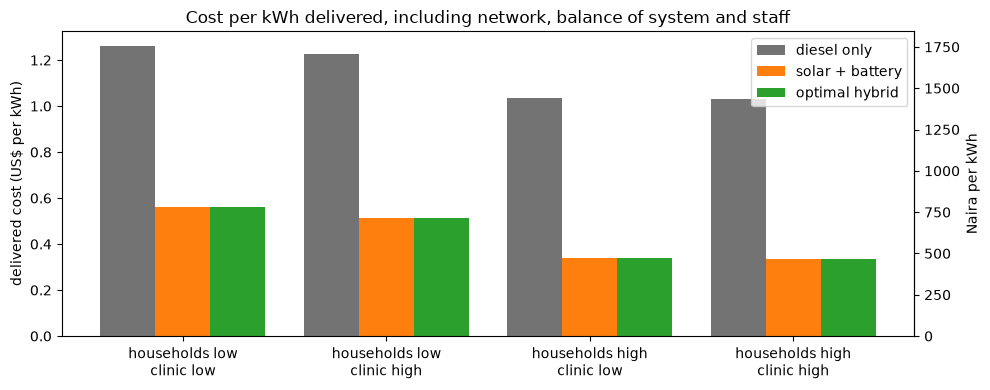

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
labels = {"diesel_only": "diesel only", "pv_battery": "solar + battery", "hybrid": "optimal hybrid"}
groups = [(dm_, cl) for dm_ in ("low", "high") for cl in ("low", "high")]
x = np.arange(len(groups)); w = 0.27
for i, (design, colour) in enumerate([("diesel_only", "0.45"), ("pv_battery", "tab:orange"), ("hybrid", "tab:green")]):
    vals = [res.loc[f"{design} | demand {a} | clinic {b}", "LCOE delivered $/kWh"] for a, b in groups]
    ax.bar(x + (i - 1) * w, vals, w, color=colour, label=labels[design])
ax.set_xticks(x, [f"households {a}\nclinic {b}" for a, b in groups])
ax.set_ylabel("delivered cost (US$ per kWh)"); ax.legend()
ax.set_title("Cost per kWh delivered, including network, balance of system and staff")
sec = ax.secondary_yaxis("right", functions=(lambda v: v * cst.FX_NGN_PER_USD, lambda v: v / cst.FX_NGN_PER_USD))
sec.set_ylabel("Naira per kWh")
fig.tight_layout(); fig.savefig(FIG / "lcoe_by_design.png", dpi=150)

## 2. How the optimised system runs

The optimal hybrid for the high household case: one dry-season week (January) and the rainy-season week with the most unserved household energy. **The optimisation knows the whole year's weather in advance**, so in the rainy week it rations households on several evenings while the battery still holds charge, to get through the cloudy spell. Section 4 shows what happens without that foresight.

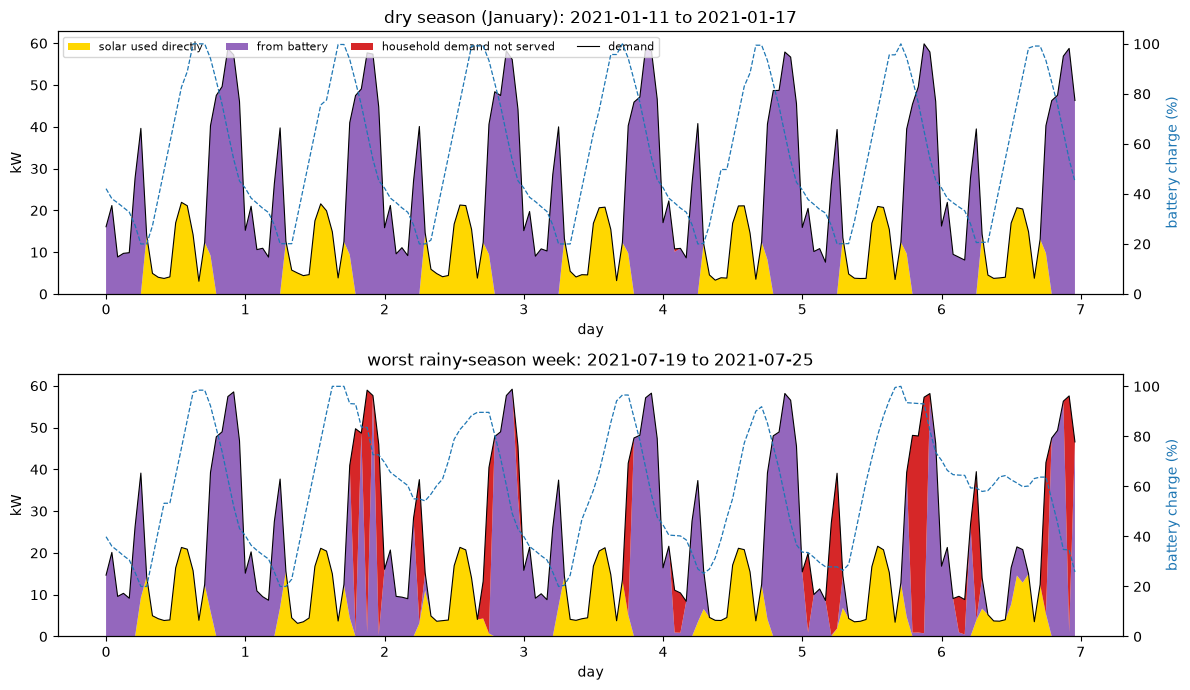

In [7]:
name = "hybrid | demand high | clinic low"
n = nets[name]
g, L = n.generators_t.p, n.loads_t.p
discharge = n.links_t.p1["inverter discharge"].abs(); charge = n.links_t.p0["inverter charge"]
soc = n.stores_t.e["battery"] / n.stores.at["battery", "e_nom_opt"]
weekly_short = g["unserved"].resample("W").sum()
weeks = {"dry season (January)": ("2021-01-11", "2021-01-17"),
         "worst rainy-season week": ((weekly_short.idxmax() - pd.Timedelta(days=6)).strftime("%Y-%m-%d"), weekly_short.idxmax().strftime("%Y-%m-%d"))}
fig, axs = plt.subplots(2, 1, figsize=(12, 7), sharey=True)
for ax, (title, (a, b)) in zip(axs, weeks.items()):
    sl = slice(a, f"{b} 23:00")
    pv_used = (g["pv"] - charge).clip(lower=0)[sl]
    t = np.arange(len(pv_used)) / 24
    ax.stackplot(t, pv_used, discharge[sl], g["unserved"][sl], colors=["gold", "tab:purple", "tab:red"],
                 labels=["solar used directly", "from battery", "household demand not served"])
    ax.plot(t, L.sum(axis=1)[sl], "k", lw=0.8, label="demand")
    ax2 = ax.twinx(); ax2.plot(t, soc[sl] * 100, color="tab:blue", lw=0.9, ls="--"); ax2.set_ylim(0, 105)
    ax2.set_ylabel("battery charge (%)", color="tab:blue")
    ax.set_title(f"{title}: {a} to {b}"); ax.set_ylabel("kW"); ax.set_xlabel("day")
axs[0].legend(loc="upper left", fontsize=8, ncol=4)
fig.tight_layout(); fig.savefig(FIG / "dispatch_weeks.png", dpi=150)

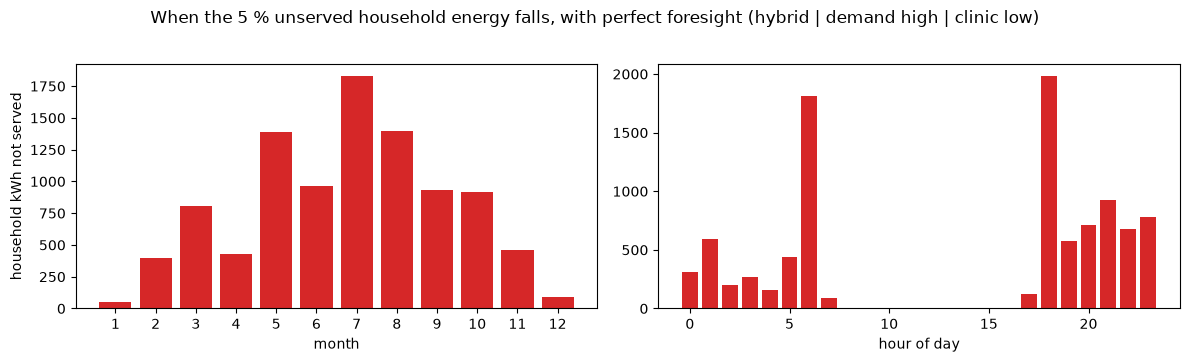

In [8]:
u = n.generators_t.p["unserved"]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
axs[0].bar(range(1, 13), u.groupby(u.index.month).sum().reindex(range(1, 13), fill_value=0), color="tab:red")
axs[0].set_xlabel("month"); axs[0].set_ylabel("household kWh not served"); axs[0].set_xticks(range(1, 13))
axs[1].bar(range(24), u.groupby(u.index.hour).sum().reindex(range(24), fill_value=0), color="tab:red")
axs[1].set_xlabel("hour of day"); axs[1].set_title("")
fig.suptitle(f"When the 5 % unserved household energy falls, with perfect foresight ({name})", y=1.02)
fig.tight_layout(); fig.savefig(FIG / "shortfall_timing.png", dpi=150, bbox_inches="tight")

## 4. Without perfect foresight

A real operator does not know next week's weather. `model.simulate_rule` runs the optimised sizes with a simple rule: solar first, then the battery down to its floor, then cut households, and the clinic and school only as a last resort. Two fixes are compared for the high household case.

In [9]:
case = m.Case(design="hybrid", demand="high", clinic="low"); n = nets[case.name]
crit_peak = (d.school + d.clinic_low).max()
rows = {"optimisation (perfect foresight)": {"households unserved %": res.loc[case.name, "unserved % of households"], "clinic/school hours cut": 0, "diesel litres/yr": 0.0}}
for label, kw in [("simple rule, no fix", {}), ("rule + 30 % battery reserve for clinic/school", {"reserve_share": 0.3}),
                  (f"rule + {np.ceil(crit_peak):.0f} kW backup generator for clinic/school", {"backup_kw": np.ceil(crit_peak)})]:
    r = m.simulate_rule(n, case, d, pv, **kw)
    rows[label] = {"households unserved %": r["unserved % of households (rule)"], "clinic/school hours cut": r["clinic/school hours cut (rule)"],
                   "diesel litres/yr": r["diesel kWh (rule)"] * cst.FUEL_L_PER_KWH}
pd.DataFrame(rows).T.round(1)

,households unserved %,clinic/school hours cut,diesel litres/yr
optimisation (perfect foresight),5.0,0.0,0.0
"simple rule, no fix",4.9,339.0,0.0
rule + 30 % battery reserve for clinic/school,12.7,0.0,0.0
rule + 3 kW backup generator for clinic/school,4.9,0.0,61.0


A battery reserve keeps the clinic on but more than doubles what households lose. A backup generator sized to the clinic and school peak keeps them on in every hour, using well under 100 litres of diesel a year. **The final design adds that backup generator** (author's choice, 26 Nov 2026); all results below come from the no-foresight rule.

In [10]:
final = pd.DataFrame([m.final_design(nets[c.name], res.loc[c.name].to_dict() | {"case": c.name}, c, d, pv)
                      for c in m.main_cases() if c.design == "hybrid"]).set_index("case")
final.to_parquet(PROC / "results_final.parquet")
final

,PV kWp,battery kWh,inverter kW,main diesel kW,backup generator kW,households unserved %,hours with household shortfall,clinic/school hours cut,diesel litres/yr,CO2 t/yr,backup capital $/yr,diesel running $/yr,total cost $/yr,LCOE delivered $/kWh,LCOE delivered N/kWh
case,,,,,,,,,,,,,,,
hybrid | demand low | clinic low,53.54,133.28,15.78,0.0,3.0,4.57,515,0,58.09,0.16,60.61,164.90,26944.89,0.57,786.40
hybrid | demand low | clinic high,62.05,141.23,16.64,0.0,5.0,4.33,460,0,92.45,0.25,101.02,262.46,28081.78,0.52,722.62
hybrid | demand high | clinic low,208.93,558.00,65.22,0.0,3.0,4.90,567,0,61.02,0.16,60.61,173.23,65454.77,0.34,475.42
hybrid | demand high | clinic high,216.78,565.12,66.50,0.0,5.0,4.84,557,0,99.80,0.27,101.02,283.33,66594.07,0.34,468.04


## 3. Against RLI's own design for Umon South

The RLI/GIZ electrification plan also sized a mini-grid for this cluster. Its assumptions (costs, diesel price, year, demand) are not in the dataset, and the units of its sizes are not stated, so this is a rough comparison.

In [11]:
import shapefile
r = shapefile.Reader(str(ds.rli_cross_river() / "cluster_phases_State_Cross River.shp"))
rli = pd.DataFrame(r.records(), columns=[f[0] for f in r.fields[1:]]).set_index("ID").loc[ds.SITE["rli_id"]]
comp = pd.DataFrame({
    "RLI design (units assumed)": {"PV kWp": rli["_PV size"], "battery kWh": rli["_Battery s"], "diesel kW": rli["_Generator"],
                                   "renewable share %": rli["_RE Share"]},
    **{f"this study, {k} demand": {"PV kWp": res.loc[f"hybrid | demand {k} | clinic low", "PV kWp"],
                                   "battery kWh": res.loc[f"hybrid | demand {k} | clinic low", "battery kWh"],
                                   "diesel kW": res.loc[f"hybrid | demand {k} | clinic low", "diesel kW"],
                                   "renewable share %": 100 - res.loc[f"hybrid | demand {k} | clinic low", "diesel share %"]}
       for k in ("low", "high")}})
comp.round(1)

,RLI design (units assumed),"this study, low demand","this study, high demand"
PV kWp,96.0,53.5,208.9
battery kWh,168.0,133.3,558.0
diesel kW,77.0,0.0,0.0
renewable share %,65.6,100.0,100.0


## What this shows

- **At today's diesel price the least-cost design is solar plus battery.** With diesel delivered at about $2.68 a litre, a kWh from a generator costs about $0.94; solar plus battery delivers for about a quarter of that. In every demand and clinic case the optimiser builds no main generator.
- **But that design leans on perfect foresight.** The optimisation keeps the clinic and school on by rationing households ahead of cloudy spells it knows are coming. Operated with a simple rule and no foresight, the same system would cut the clinic and school for about 330 hours a year.
- **A small backup generator fixes it cheaply.** A 3-5 kW generator that serves only the clinic and school when the battery is empty keeps them on in every hour, burns about 60-100 litres of diesel a year, and adds about $220-380 a year. Households still go without about 4.3-4.9 % of their energy, on roughly 460-570 hours a year, mostly rainy-season evenings.
- **Final design, high household demand:** about 209-217 kWp of PV, 558-565 kWh of battery, a 65-67 kW inverter and a 3-5 kW backup generator, delivering at about **$0.34 per kWh (₦468-475)**. Low household demand: 54-62 kWp, 133-141 kWh, delivering at **$0.52-0.57 per kWh (₦723-786)**, dearer per kWh because the network, balance of system and staff are spread over fewer kWh. Diesel only would cost $1.03-1.26 per kWh.
- **The battery works hard.** It cycles about 325 times a year, a little above the 300 a year that 3,000 cycles over 10 years allows, so it wears out after about 9.2 years; that cost is included.
- **RLI's own design for this cluster** includes a 77 kW generator and a smaller battery, made under different, unstated assumptions, most likely much cheaper diesel. Notebook 03's diesel-price sweep shows at what price a main generator comes back.

**Limits.** One typical weather year (no run of unusually cloudy years). A linear generator model (no minimum load or start-up cost). Battery wear counted after the fact. Median ESMAP costs, not quotes for this site. The no-foresight rule is deliberately simple; a smarter controller would do somewhat better than it.